In [46]:
## Script for extracting and processing fMRI physio data
# Uses code from here: https://github.com/cbinyu/bidsphysio
# Run with python 3.10 fMRI env
# James Fodor 2024

import os
import re
import shutil
import zipfile
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import find_peaks
from scipy.signal import savgol_filter
from scipy.interpolate import interp1d
from bidsphysio.dcm2bids import dcm2bidsphysio

# set numpy display option
np.set_printoptions(precision=3, threshold=5000, linewidth=220, suppress=True, floatmode='fixed')
sns.set()

In [ ]:
## Define functions for use in this notebook

# Unzip compressed folders
def extract_archives(main_folder):
    for root, dirs, files in os.walk(main_folder):
        for file in files:
            if file.endswith(".zip"):
                zip_path = os.path.join(root, file)
                extract_path = os.path.splitext(zip_path)[0]
                with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                    zip_ref.extractall(extract_path)
                os.remove(zip_path)  # Delete the archive file after extraction
                    

# Extract and rename .dcm physio files
def find_and_copy_dcm_files(main_folder):
    for root, dirs, files in os.walk(main_folder):
        for file in files:
            full_path = os.path.join(root, file)
            if file.endswith(".dcm") and ("dicom_series" in full_path): # only get unprocessed physio files
                subject_id = str(full_path[115:120].split('.')[1])
                subject_id = str(int(subject_id)-1) # decrement by one to adjust to my numbering
                if len(subject_id)==1: # pad leading zero when needed
                    subject_id='0'+subject_id
                sub_folder = main_folder+'sub-'+subject_id+'\\phys'
                
                if not os.path.exists(sub_folder):
                    os.makedirs(sub_folder)

                # Use the entire existing path as the new filename
                full_path_name = os.path.relpath(full_path, main_folder).replace(os.path.sep, '_')
                run_match = re.search(r'Run(\d+)', full_path_name)
                run_number = run_match.group(1)
                new_filename = 'sub-'+subject_id+'_physio_run'+str(run_number)+'.dcm'
                destination_path = os.path.join(sub_folder, new_filename)
                shutil.copy(full_path, destination_path)
                print(f'Moved: {full_path} to {destination_path}')
                
                
# Append a new item to a json file
def add_entry_to_json(filename, new_key, new_value):
    new_entry = {new_key: new_value}

    with open(filename) as f:
        data = json.load(f)

    data.update(new_entry)

    with open(filename, 'w') as f:
        json.dump(data, f, indent=0)


# Adjust numbers of saved filed if I make a mistake
def decrement_numbers_in_paths(root_dir):
    # Walk through all files and directories in root_dir
    for root, dirs, files in os.walk(root_dir):
        for filename in files:
            # Construct the full file path
            full_path = os.path.join(root, filename)
            
            # Find all numbers in the file path
            numbers = re.findall(r'sub-\d+', full_path)
            
            # Decrement each number found by one
            new_path = full_path
            for num_str in numbers:
                num_str = num_str.split('-')[1]
                num = int(num_str)
                new_num_str = str(num - 1).zfill(2)
                new_path = new_path.replace(num_str, new_num_str, 1)  # Replace only the first occurrence
            
            # Rename the file with the updated path
            if new_path != full_path:
                try:
                    shutil.move(full_path, new_path)
                    print(f'Renamed "{full_path}" to "{new_path}"')
                except Exception as e:
                    print(f'Failed to rename "{full_path}": {e}')


In [22]:
## Define key parameters
run_duration = 508.8 # in seconds
sampling_rate = 50 # times per second

In [ ]:
## Extract physio data from .dcd to .tsv files (only do once)

if (0):
    # Extract and prepare physio data files (need to be downloaded separately)
    # Before running, place .zip files in the 'Physio Data' folder (not in subject subfolders)
    main_folder = 'path/to/dcms'
    extract_archives(main_folder)
    find_and_copy_dcm_files(main_folder)

    # Extract physio data from .dcd to .tsv files
    subject_id = '45' # specify subject ID to process
    num_runs = 8
    physio_directory = main_folder+'sub-'+subject_id+'\\phys'

    # loop over all .dcm files in the physio directory
    all_runs_stacked = []
    for filename in os.listdir(physio_directory):
        if filename.endswith('.dcm'): # only .dcm files
            # Get run number
            run_match = re.search(r'run(\d+)', filename)
            run_number = run_match.group(1)
            input_path = os.path.join(physio_directory, filename)
            
            # Load and organise physio data from dcm file
            data_store = dcm2bidsphysio.dcm2bids(input_path, 'physio') # get the actual data
            cardio_data = data_store.signals[0].signal[3::4].astype('str') # zero index is pulse data; get every fourth value as sampling is different to respir for some reason
            respir_data = data_store.signals[1].signal.astype('str') # one index is resp data
            # data_store.save_to_bids(f"run{run_number}_data") # this line saves some json files with start and sampling frequency info
            start_index = int(19.18*sampling_rate) # start time times sampling rate; this can be found by looking at the 'start time' in the .json files
            cardio_data_adj = np.array([num if num != 'nan' else 0 for num in cardio_data]).astype('float')[start_index:] # replace nans with 0s and exclude readings before first trigger
            respir_data_adj = np.array([num if num != 'nan' else 0 for num in respir_data]).astype('float')[start_index:]
            trigger = np.zeros(max(len(cardio_data_adj), len(respir_data_adj)))
            trigger[0] = 1  # set first value to 1 to indicate start of recording
            
            # Combine and save data with json in BIDS format
            arrays = [cardio_data_adj, respir_data_adj, trigger]
            max_len = max(a.shape[0] for a in arrays)
            padded_arrays = [np.pad(a, (0,max_len-a.shape[0]), mode="constant") for a in arrays]
            stacked_arrays = np.vstack(padded_arrays).T
            all_runs_stacked.append(stacked_arrays)
            np.savetxt("sub-"+subject_id+"_task-sentences_run-"+str(run_number)+"_physio.tsv", stacked_arrays, delimiter='\t', fmt='%i')
            json.dump({ "Columns": ["cardiac", "respiratory", "trigger"],
                        "SamplingFrequency": sampling_rate,
                        "StartTime": 0.0},
                        open("sub-"+subject_id+"_task-sentences_run-"+str(run_number)+"_physio.json", "w"), indent=2)

            # Save alternative formats if needed
            # output_cardio = "sub-"+subject_id+"_cardio_run"+run_number+".tsv" # specify output name
            # output_respir = "sub-"+subject_id+"_respir_run"+run_number+".tsv"
            # np.savetxt(os.path.join(physio_directory, output_cardio), cardio_data_adj, delimiter='\t', fmt='%s')
            # np.savetxt(os.path.join(physio_directory, output_respir), respir_data_adj, delimiter='\t', fmt='%s')


Parsing waveform 0
Data length     : 13107257
Filename length : 67
Filename        : b'Physio_20240808_100351_7dd7996e-cbde-4305-a945-6cd316e9eefe_ECG.log'
UUID            : 7dd7996e-cbde-4305-a945-6cd316e9eefe
Scan date       : 20240808_100351
Waveform type   : ECG

Parsing waveform 1
Data length     : 3254587
Filename length : 68
Filename        : b'Physio_20240808_100351_7dd7996e-cbde-4305-a945-6cd316e9eefe_PULS.log'
UUID            : 7dd7996e-cbde-4305-a945-6cd316e9eefe
Scan date       : 20240808_100351
Waveform type   : PULS

Parsing waveform 2
Data length     : 818998
Filename length : 68
Filename        : b'Physio_20240808_100351_7dd7996e-cbde-4305-a945-6cd316e9eefe_RESP.log'
UUID            : 7dd7996e-cbde-4305-a945-6cd316e9eefe
Scan date       : 20240808_100351
Waveform type   : RESP

Parsing waveform 3
Data length     : 2938606
Filename length : 68
Filename        : b'Physio_20240808_100351_7dd7996e-cbde-4305-a945-6cd316e9eefe_Info.log'
UUID            : 7dd7996e-cbde-4305-a

In [70]:
## Load physio data into list of numpy arrays

# Specify parameters
sub_id = '44' # specify subject ID to process
num_runs = 8
main_folder = '../Data-fmri/physio/sub-'+sub_id+'/phys/'
all_data = []

# Loop over cardio and respiratory data types
for data_type in ['cardio', 'respir']:
    
    # Load files into list of arrays
    all_runs_list = []
    for run in np.arange(1, num_runs+1):
        run_data = np.loadtxt(main_folder+"sub-"+sub_id+"_"+data_type+"_run"+str(run)+".tsv", delimiter='\t')
        all_runs_list.append(run_data)

    # Combine all runs into single array
    all_runs_stacked = []
    max_len = max(a.shape[0] for a in all_runs_list)
    padded_arrays = [np.pad(a, (0,max_len-a.shape[0]), mode="constant") for a in all_runs_list]
    all_runs_stacked = np.vstack(padded_arrays)
    print(all_runs_stacked.shape)
    
    # Combine cardio and respiratory data into single array
    all_data.append(all_runs_stacked)

(8, 25439)
(8, 25439)


length record: 0.16 seconds




Points removed: 498 out of 5241
Mean heart rate: 75.14
Std heart rate: 5.47




Points removed: 401 out of 1506
Mean breathing rate: 19.44
Std breathing rate: 7.33


In [76]:
## Extract pulse and breathing data from physio files

# Combine all runs into single array
print('length record:',all_data[0].shape[0]/sampling_rate,'seconds')

# Loop over cardio and respiratory data
rate_store = []
time_store = []
z_cutoffs = [4,4]
for type in [0,1]:

    # Prepare data for processing
    data = all_data[type]
    data[data == 'nan'] = 0 # replace zeros with nan
    data = data.reshape(-1) # flatten into single array

    # Extract and plot peaks
    peaks, _ = find_peaks(data, prominence=300)
    plt.figure(figsize=(300,4))
    # plt.xlim(0,run_duration*sampling_rate*num_runs)
    plt.plot(peaks, data[peaks], "ob")
    plt.plot(data, linewidth=0.3)
    plt.show()

    # Determing timing between peaks and convert to rate
    time_gap = np.array([peaks[i + 1] - peaks[i] for i in range(len(peaks)-1)])/sampling_rate # time between peaks in seconds
    rate = (1/time_gap)*60 # convert to per minute
    time_in_sec = peaks[1:]/sampling_rate

    # Get mean and std of rate
    mean_rate = np.mean(rate)
    median_rate = np.median(rate)
    std_rate = np.std(rate)
    mad_rate = np.median([abs(x - median_rate) for x in rate])
    
    # Remove outlier points from data; set to median of neighbouring points
    points_removed = 0
    for idx,single_rate in enumerate(rate):
        robust_z = (single_rate - median_rate) / (1.4826 * mad_rate)
        if np.abs(robust_z)>z_cutoffs[type]:
            local_window = 120 # number of points to consider around outlier
            min_local_index = np.max([0,idx-local_window])
            max_local_index = np.min([idx+local_window,len(rate)-1])
            rate[idx] = np.nanmedian(rate[min_local_index:max_local_index])
            points_removed+=1

    # Store cleaned data
    rate_store.append(rate)
    time_store.append(time_in_sec)

    # Print summary statistics
    print('Points removed:',points_removed,'out of',len(rate))
    if type==0:
        print('Mean heart rate: {:.2f}'.format(np.nanmean(rate)))
        print('Std heart rate: {:.2f}'.format(np.nanstd(rate)))
    elif type==1:
        print('Mean breathing rate: {:.2f}'.format(np.nanmean(rate)))
        print('Std breathing rate: {:.2f}'.format(np.nanstd(rate)))


(8, 636)


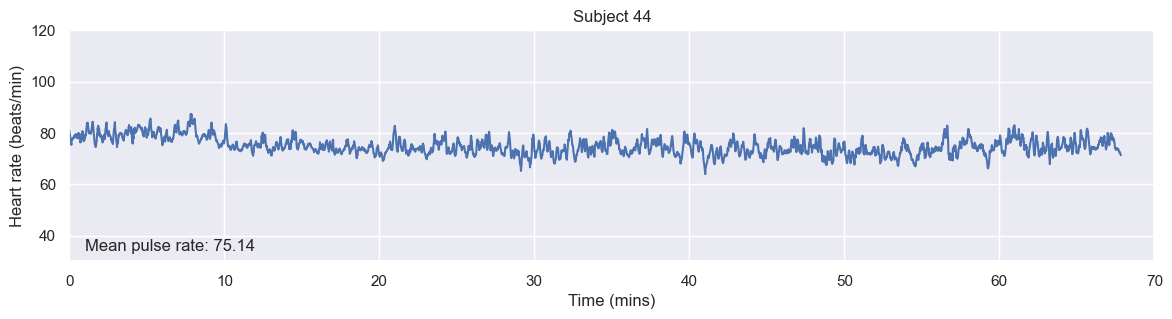

(8, 636)


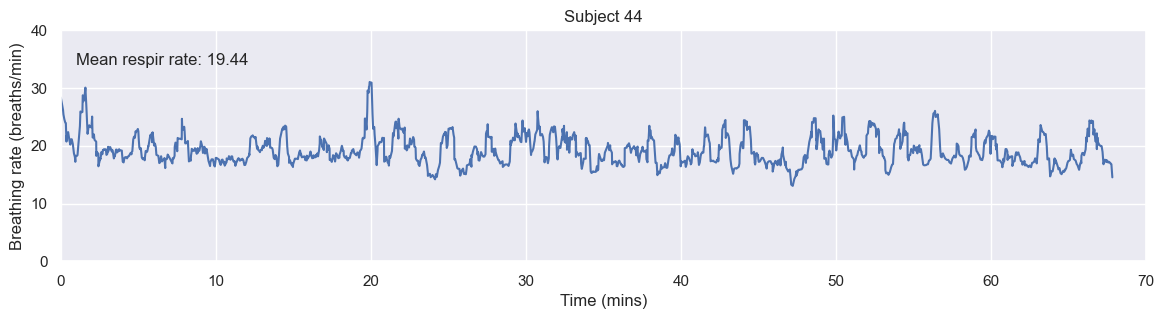

In [78]:
## Plot physio rates over time

# Loop over cardio and respiratory data
for type in [0,1]:

    # Specify type-specific parameters 
    if type==0:
        rate_label = 'Heart rate (beats/min)'
        y_max = 120
        y_min = 30
        smooth_window = 10
        file_name = 'pulse'
    elif type==1:
        rate_label = 'Breathing rate (breaths/min)'
        y_max = 40
        y_min = 0
        smooth_window = 10
        file_name = 'respir'

    # Set up figure
    plt.figure(figsize=(14,3))
    plt.ylim(y_min,y_max)
    plt.xlim(0,70)
    plt.title('Subject '+sub_id)
    plt.ylabel(rate_label)
    plt.xlabel('Time (mins)')
    plt.text(1, 34, 'Mean '+file_name+' rate: {:.2f}'.format(np.nanmean(rate_store[type])))

    # Prepare data
    rate_smooth = savgol_filter(rate_store[type], window_length=smooth_window, polyorder=1) # smooth data with filter
    rate_interpolated = interp1d(time_store[type], rate_smooth, kind='linear', bounds_error=False, fill_value='extrapolate')
    xs = np.arange(run_duration*num_runs, step=0.01)
    ys = rate_interpolated(xs)

    # Save estimated rate at each TR
    TR_xs = np.arange(num_runs*run_duration, step=0.8)
    TR_rate = rate_interpolated(TR_xs)
    TR_rate_byrun = TR_rate.reshape((num_runs, -1))
    np.savetxt("sub-"+sub_id+"_"+file_name+"_by_TR.txt", TR_rate_byrun, delimiter=' ', fmt='%f')
    print(TR_rate_byrun.shape)

    # Produce figure
    plt.plot(xs/60, ys)
    plt.savefig('sub-'+sub_id+'_'+file_name+'.png')
    plt.show()